KNAPSACK OPTIMIZATION USING GENETIC ALGORITHM

GENETIC ALGORITHM SOLUTION
--------------------------
Laptop          Weight:  8 Value: 20
Books           Weight:  3 Value:  8
Camera          Weight:  5 Value: 12
Water Bottle    Weight:  1 Value:  3
Jacket          Weight:  4 Value:  9
Charger         Weight:  1 Value:  4
Power Bank      Weight:  3 Value:  7
Total weight: 25
Total value: 63

GREEDY BASELINE SOLUTION
------------------------
Laptop          Weight:  8 Value: 20
Books           Weight:  3 Value:  8
Headphones      Weight:  2 Value:  5
Camera          Weight:  5 Value: 12
Water Bottle    Weight:  1 Value:  3
Charger         Weight:  1 Value:  4
Snacks          Weight:  2 Value:  4
Power Bank      Weight:  3 Value:  7
Total weight: 25
Total value: 63

EXACT OPTIMAL SOLUTION
----------------------
Laptop          Weight:  8 Value: 20
Books           Weight:  3 Value:  8
Headphones      Weight:  2 Value:  5
Camera          Weight:  5 Value: 12
Water Bottle    Weight:  1 Value

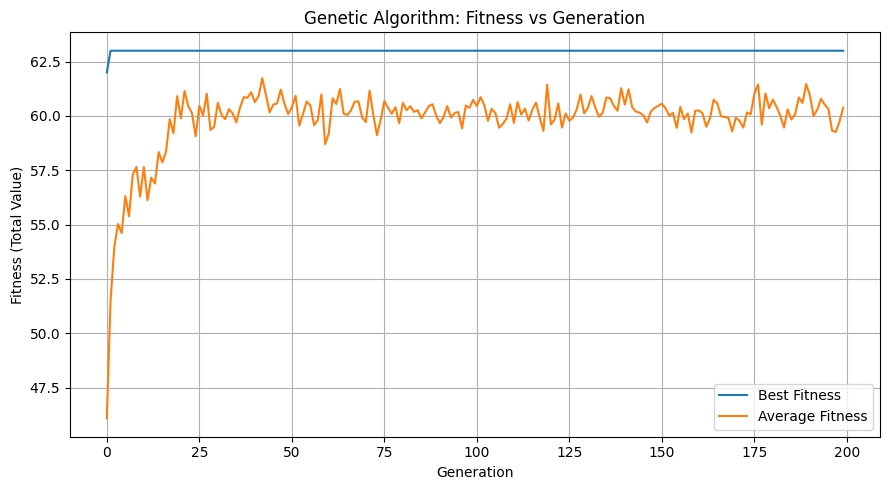


POPULATION SIZE EXPERIMENT
Size | Mean Fitness | Best | Worst | Mean Time (s)
  20 |        62.80 |   63 |    62 | 0.0849
  50 |        63.00 |   63 |    63 | 0.3523
  80 |        63.00 |   63 |    63 | 0.5964
 120 |        63.00 |   63 |    63 | 0.3672


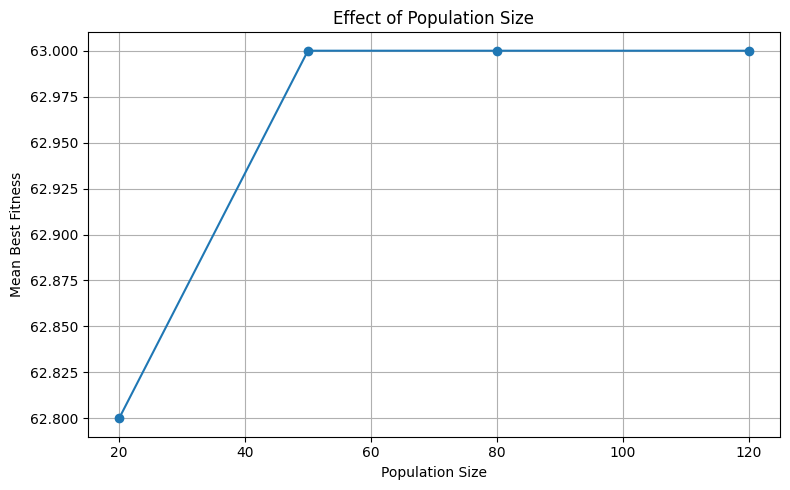


MUTATION RATE EXPERIMENT
Rate | Mean Fitness | Best | Worst | Mean Time (s)
0.005 |        62.60 |   63 |    62 | 0.3472
0.030 |        63.00 |   63 |    63 | 0.2443
0.100 |        63.00 |   63 |    63 | 0.2539
0.200 |        63.00 |   63 |    63 | 0.2584


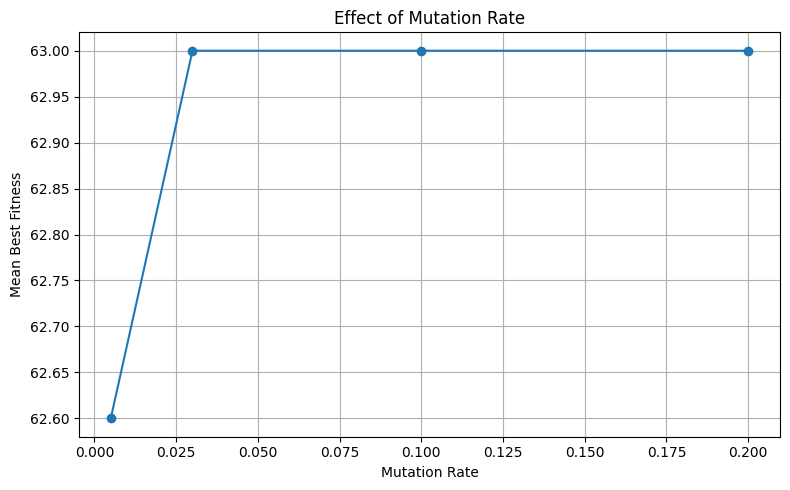


PROJECT COMPLETED SUCCESSFULLY!
Generated files:
1. fitness_vs_generation.png
2. population_size_comparison.png
3. mutation_rate_comparison.png
4. fitness_history.csv
5. parameter_experiments.csv


In [ ]:

import random
import time
import csv
import matplotlib.pyplot as plt

# ============================================================
# EVOLUTIONARY COMPUTING PBL
# Knapsack Optimization using a Genetic Algorithm
# ============================================================

ITEMS = [
    ("Laptop", 8, 20),
    ("Books", 3, 8),
    ("Headphones", 2, 5),
    ("Camera", 5, 12),
    ("Water Bottle", 1, 3),
    ("Jacket", 4, 9),
    ("Charger", 1, 4),
    ("Shoes", 6, 13),
    ("Snacks", 2, 4),
    ("Notebook", 1, 2),
    ("Power Bank", 3, 7),
    ("Tablet", 5, 11)
]

CAPACITY = 25
WEIGHTS = [item[1] for item in ITEMS]
VALUES = [item[2] for item in ITEMS]
N = len(ITEMS)


# ---------------- FITNESS FUNCTION ----------------
def fitness(chromosome):
    total_weight = sum(
        chromosome[i] * WEIGHTS[i] for i in range(N)
    )
    total_value = sum(
        chromosome[i] * VALUES[i] for i in range(N)
    )

    if total_weight > CAPACITY:
        return 0

    return total_value


def total_weight(chromosome):
    return sum(
        chromosome[i] * WEIGHTS[i] for i in range(N)
    )


# ---------------- CREATE INITIAL POPULATION ----------------
def create_chromosome():
    chromosome = [random.randint(0, 1) for _ in range(N)]

    # Repair overweight solutions
    while total_weight(chromosome) > CAPACITY:
        selected = [i for i in range(N) if chromosome[i] == 1]
        chromosome[random.choice(selected)] = 0

    return chromosome


def create_population(population_size):
    return [create_chromosome() for _ in range(population_size)]


# ---------------- PARENT SELECTION ----------------
def tournament_selection(population):
    contestants = random.sample(population, 3)
    return max(contestants, key=fitness)


# ---------------- CROSSOVER ----------------
def crossover(parent1, parent2, crossover_rate=0.8):
    if random.random() > crossover_rate:
        return parent1[:], parent2[:]

    point = random.randint(1, N - 1)
    child1 = parent1[:point] + parent2[point:]
    child2 = parent2[:point] + parent1[point:]

    return child1, child2


# ---------------- MUTATION ----------------
def mutate(chromosome, mutation_rate=0.03):
    child = chromosome[:]

    for i in range(N):
        if random.random() < mutation_rate:
            child[i] = 1 - child[i]

    # Repair overweight offspring
    while total_weight(child) > CAPACITY:
        selected = [i for i in range(N) if child[i] == 1]
        child[random.choice(selected)] = 0

    return child


# ---------------- GENETIC ALGORITHM ----------------
def genetic_algorithm(
    population_size=80,
    generations=200,
    mutation_rate=0.03,
    crossover_rate=0.8,
    seed=42
):
    random.seed(seed)
    population = create_population(population_size)

    best_history = []
    mean_history = []

    best = max(population, key=fitness)

    start_time = time.perf_counter()

    for generation in range(generations):
        # Elitism: preserve the best solution
        current_best = max(population, key=fitness)

        if fitness(current_best) > fitness(best):
            best = current_best[:]

        scores = [fitness(individual) for individual in population]
        best_history.append(max(scores))
        mean_history.append(sum(scores) / len(scores))

        new_population = [best[:]]

        while len(new_population) < population_size:
            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)

            child1, child2 = crossover(
                parent1, parent2, crossover_rate
            )

            child1 = mutate(child1, mutation_rate)
            child2 = mutate(child2, mutation_rate)

            new_population.append(child1)

            if len(new_population) < population_size:
                new_population.append(child2)

        population = new_population

    # Check the final population too
    current_best = max(population, key=fitness)

    if fitness(current_best) > fitness(best):
        best = current_best[:]

    elapsed = time.perf_counter() - start_time

    return best, best_history, mean_history, elapsed


# ---------------- GREEDY BASELINE ----------------
def greedy_solution():
    chromosome = [0] * N

    # Choose items by value-to-weight ratio
    order = sorted(
        range(N),
        key=lambda i: VALUES[i] / WEIGHTS[i],
        reverse=True
    )

    remaining_capacity = CAPACITY

    for i in order:
        if WEIGHTS[i] <= remaining_capacity:
            chromosome[i] = 1
            remaining_capacity -= WEIGHTS[i]

    return chromosome


# ---------------- EXACT SOLUTION ----------------
def exact_solution():
    # Dynamic programming: finds the true optimal value
    dp = [[0] * (CAPACITY + 1) for _ in range(N + 1)]

    for i in range(1, N + 1):
        weight = WEIGHTS[i - 1]
        value = VALUES[i - 1]

        for capacity in range(CAPACITY + 1):
            dp[i][capacity] = dp[i - 1][capacity]

            if weight <= capacity:
                dp[i][capacity] = max(
                    dp[i][capacity],
                    dp[i - 1][capacity - weight] + value
                )

    chromosome = [0] * N
    remaining_capacity = CAPACITY

    for i in range(N, 0, -1):
        if dp[i][remaining_capacity] != dp[i - 1][remaining_capacity]:
            chromosome[i - 1] = 1
            remaining_capacity -= WEIGHTS[i - 1]

    return chromosome


# ---------------- DISPLAY SELECTED ITEMS ----------------
def display_solution(title, chromosome):
    print("\n" + title)
    print("-" * len(title))

    for i, selected in enumerate(chromosome):
        if selected:
            print(
                f"{ITEMS[i][0]:15s} "
                f"Weight: {WEIGHTS[i]:2d} "
                f"Value: {VALUES[i]:2d}"
            )

    print("Total weight:", total_weight(chromosome))
    print("Total value:", fitness(chromosome))


# ---------------- MAIN EXPERIMENT ----------------
print("=" * 60)
print("KNAPSACK OPTIMIZATION USING GENETIC ALGORITHM")
print("=" * 60)

best, best_history, mean_history, elapsed = genetic_algorithm()

display_solution("GENETIC ALGORITHM SOLUTION", best)

greedy = greedy_solution()
display_solution("GREEDY BASELINE SOLUTION", greedy)

exact = exact_solution()
display_solution("EXACT OPTIMAL SOLUTION", exact)

print("\nGA execution time:", round(elapsed, 4), "seconds")
print("GA reached optimal value:", fitness(best) == fitness(exact))


# ---------------- GRAPH 1: FITNESS OVER GENERATIONS ----------------
plt.figure(figsize=(9, 5))
plt.plot(best_history, label="Best Fitness")
plt.plot(mean_history, label="Average Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness (Total Value)")
plt.title("Genetic Algorithm: Fitness vs Generation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("fitness_vs_generation.png", dpi=150)
plt.show()


# ---------------- EXPERIMENT 1: POPULATION SIZE ----------------
population_sizes = [20, 50, 80, 120]
population_results = []

for size in population_sizes:
    scores = []
    runtimes = []

    for seed in range(5):
        solution, _, _, run_time = genetic_algorithm(
            population_size=size,
            generations=200,
            mutation_rate=0.03,
            seed=seed
        )

        scores.append(fitness(solution))
        runtimes.append(run_time)

    population_results.append((
        size,
        sum(scores) / len(scores),
        max(scores),
        min(scores),
        sum(runtimes) / len(runtimes)
    ))

print("\nPOPULATION SIZE EXPERIMENT")
print("Size | Mean Fitness | Best | Worst | Mean Time (s)")

for result in population_results:
    print(
        f"{result[0]:4d} | {result[1]:12.2f} | "
        f"{result[2]:4d} | {result[3]:5d} | {result[4]:.4f}"
    )

plt.figure(figsize=(8, 5))
plt.plot(
    [r[0] for r in population_results],
    [r[1] for r in population_results],
    marker="o"
)
plt.xlabel("Population Size")
plt.ylabel("Mean Best Fitness")
plt.title("Effect of Population Size")
plt.grid(True)
plt.tight_layout()
plt.savefig("population_size_comparison.png", dpi=150)
plt.show()


# ---------------- EXPERIMENT 2: MUTATION RATE ----------------
mutation_rates = [0.005, 0.03, 0.10, 0.20]
mutation_results = []

for rate in mutation_rates:
    scores = []
    runtimes = []

    for seed in range(5):
        solution, _, _, run_time = genetic_algorithm(
            population_size=80,
            generations=200,
            mutation_rate=rate,
            seed=seed
        )

        scores.append(fitness(solution))
        runtimes.append(run_time)

    mutation_results.append((
        rate,
        sum(scores) / len(scores),
        max(scores),
        min(scores),
        sum(runtimes) / len(runtimes)
    ))

print("\nMUTATION RATE EXPERIMENT")
print("Rate | Mean Fitness | Best | Worst | Mean Time (s)")

for result in mutation_results:
    print(
        f"{result[0]:4.3f} | {result[1]:12.2f} | "
        f"{result[2]:4d} | {result[3]:5d} | {result[4]:.4f}"
    )

plt.figure(figsize=(8, 5))
plt.plot(
    [r[0] for r in mutation_results],
    [r[1] for r in mutation_results],
    marker="o"
)
plt.xlabel("Mutation Rate")
plt.ylabel("Mean Best Fitness")
plt.title("Effect of Mutation Rate")
plt.grid(True)
plt.tight_layout()
plt.savefig("mutation_rate_comparison.png", dpi=150)
plt.show()


# ---------------- SAVE CSV RESULTS ----------------
with open("fitness_history.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["Generation", "Best Fitness", "Mean Fitness"])

    for i, (best_score, mean_score) in enumerate(
        zip(best_history, mean_history)
    ):
        writer.writerow([i, best_score, mean_score])


with open("parameter_experiments.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow([
        "Experiment", "Parameter", "Mean Fitness",
        "Best Fitness", "Worst Fitness", "Mean Runtime Seconds"
    ])

    for r in population_results:
        writer.writerow(["Population Size", r[0], *r[1:]])

    for r in mutation_results:
        writer.writerow(["Mutation Rate", r[0], *r[1:]])


print("\n" + "=" * 60)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("Generated files:")
print("1. fitness_vs_generation.png")
print("2. population_size_comparison.png")
print("3. mutation_rate_comparison.png")
print("4. fitness_history.csv")
print("5. parameter_experiments.csv")
print("=" * 60)

In [ ]:

from google.colab import files

files.download("fitness_vs_generation.png")
files.download("population_size_comparison.png")
files.download("mutation_rate_comparison.png")
files.download("fitness_history.csv")
files.download("parameter_experiments.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>